# Диагностика переноса стилевого профиля в модели признаков с идентификационной компонентой

**Вычислительный эксперимент по статье Н. Ю. Быковского · версия исследования 5.0**

Один и тот же объект можно сопоставить со своим эталоном по двум причинам: из-за сходства стилевых профилей и из-за совпадения идентификационного кода. Здесь оба механизма заданы явно. Это позволяет проверить, какой вывод о переносе стиля обоснован при известной структуре данных.

Ноутбук генерирует исходные векторы, перебирает параметры модели, воспроизводит две перестановочные проверки и вычисляет границы равной точности. Все численные таблицы и графики строятся при выполнении ячеек. Исследование относится к синтетическим признакам; аудиозаписи, синтезаторы речи и оценки слушателей в эксперимент не входят.

### Как воспроизвести расчёт

Откройте файл в JupyterLab или VS Code с Python-ядром и выполните все ячейки сверху вниз. В обычном окружении достаточно установить зависимости командой `python -m pip install jupyterlab ipykernel numpy==2.3.5 pandas`. Для точного сравнения со статьёй используйте Python 3.12 и NumPy 2.3.5. Выборки создаются локально, сетевых запросов и входных файлов нет.

1. **Модель и точность.** Пять кандидатов, два семейства распределений, полная сетка из 240 условий и два отдельных запуска.
2. **Идентификационное смешение.** Контрпример, чувствительность к шуму и численные пары с одинаковой точностью.
3. **Проверки гипотез.** Общий блочный тест, парный контроль и границы частоты отклонений.
4. **Верификация и применение.** Сверка с контрольными значениями статьи, иллюстрация планирования мощности и выгрузка таблиц по желанию.

Время расчёта зависит от процессора. Установленные объёмы соответствуют статье. Повторное выполнение ячеек с теми же параметрами и начальными состояниями воспроизводит выборки.

**Настройки.** Объём сетки задаёт `GRID_REPLICATIONS`, число реализаций тестов — `N_TEST`, уровень значимости — `ALPHA`. После изменения настройки повторите выполнение с ячейки, где она объявлена. Для единичного примера в разделе «Собственное условие» достаточно изменить список `conditions`.

In [1]:
import itertools
import math
import platform
from html import escape
from io import BytesIO
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

import numpy as np
import pandas as pd
from IPython.display import HTML, SVG, display

print(f"Python {platform.python_version()} · NumPy {np.__version__} · pandas {pd.__version__}")

ModuleNotFoundError: No module named 'pandas'

### Как читать обозначения

| Символ | Что обозначает |
|---|---|
| $i,j,t$ | Индексы запроса, эталона и общего для них повтора. Кандидаты выбираются внутри одной группы. |
| $s_i,u_i$ | Скрытый профиль объекта и независимый четырёхмерный профиль. |
| $\rho$ | Корреляция скрытого профиля со смесью, входящей в запрос, до добавления возмущения и шума. |
| $\tau$ | Масштаб межсеансового возмущения запроса. |
| $\lambda$ | Вес ортогонального кода объекта. При разных кодах добавка к квадрату расстояния равна $2\lambda^2$. |
| $A$ | Средняя доля правильного выбора эталона. При пяти равновероятных кандидатах случайный уровень равен 0,20. |
| $\alpha$ | Уровень значимости перестановочной проверки. В основном эксперименте $\alpha=0{,}05$. |

Четыре координаты профиля условны. Им не приписываются конкретные акустические значения, например длительность паузы или частота основного тона.

### Размерности и возвращаемые значения

Буква $R$ обозначает число независимых реализаций. Векторизованные функции сохраняют ось реализации, чтобы стандартная ошибка оценивалась по независимым выборкам.

| Функция | Вход | Результат |
|---|---|---|
| `base(seed, r, dist)` | Начальное состояние, $R$, семейство `normal` или `t3` | Пять массивов: скрытый профиль, независимый профиль, эталон, сеансовая компонента и остаточный шум запроса. |
| `distances(b, rho, tau)` | Модельная выборка и параметры запроса | Массив квадратов стилевых расстояний $R × 2 × 5 × 5 × 12$. Средние две оси размера 5 относятся к запросу и кандидату внутри группы. |
| `contaminate(d, lam)` | Стилевые расстояния и вес кода | Массив тех же размеров с добавленным вкладом идентичности. |
| `scores(d)` | Расстояния с учётом выбранного веса | Вектор длины $R$. В каждой реализации усредняются результаты 120 выборов: десять объектов по двенадцать повторов. |
| `enumerate_block_test(d, weights)` | Стилевые расстояния до добавления кода, последовательность весов | Матрица точных $p$-значений «вес × реализация» и, по запросу, индивидуальные границы для квадрата веса. |
| `exact_paired_p(differences)` | $R × 10$ средних парных разностей | По одному точному одностороннему $p$-значению на реализацию. |

Усреднение по повторам учитывается внутри объекта. При перестановках его повторы всегда остаются вместе.

## Генератор числовых профилей

В каждой реализации моделируются две независимые группы по пять объектов. Эталон и запрос принадлежат одному из десяти объектов и наблюдаются на двенадцати повторах. Сравнение допустимо только внутри группы и только для одного и того же повтора. Четыре координаты профиля условны: акустические измерения в генератор не входят.

Для объекта $i$ на повторе $t$ эталон $a$ и запрос $q$ определены формулами

$$
a_{it}=s_i+0{,}25b_i+0{,}35\varepsilon_{it},
\qquad
q_{it}=\rho s_i+\sqrt{1-\rho^2}\,u_i+\tau c_i+0{,}35\eta_{it}.
$$

$s_i$ задаёт профиль объекта, $u_i$ — независимый профиль, $b_i$ и $c_i$ — межсеансовую вариацию эталона и запроса. Величины $\varepsilon_{it}$ и $\eta_{it}$ описывают шум отдельных повторов. Все исходные координаты независимы и имеют нулевое среднее и единичную дисперсию. Сравниваются нормальное распределение и распределение Стьюдента с тремя степенями свободы, делённое на $\sqrt{3}$. Параметр $\rho$ задаёт корреляцию скрытых профилей до добавления сеансовых эффектов и шума.

Оси исходных массивов соответствуют реализации, группе, объекту, повтору и координате. У переменных, общих для всех повторов объекта, длина оси повторов равна единице. Генератор с фиксированным состоянием PCG64 и порядок выборок воспроизводят вычислительный пакет версии 5.0.

In [ ]:
from itertools import product
from math import sqrt

N, T, D = 10, 12, 4
GROUP_COUNT, GROUP_SIZE = 2, 5
RHOS = (0.0, 0.25, 0.5, 0.75, 1.0)
TAUS = (0.0, 0.5, 1.0, 2.0)
LAMS = (0.0, 0.25, 0.5, 1.0, 2.0, 4.0)
DISTS = ("normal", "t3")
GRID_SEEDS = (20261031, 20261101)
GRID_REPLICATIONS = 1000
FOREIGN_REFERENCE = 1.0 - np.eye(GROUP_SIZE)


def draw(rng, shape, dist):
    if dist == "normal":
        return rng.normal(size=shape)
    if dist == "t3":
        return rng.standard_t(3, size=shape) / sqrt(3)
    raise ValueError(f"Неизвестное распределение: {dist}")


def base(seed, r, dist):
    if r < 1:
        raise ValueError("Число реализаций должно быть положительным")
    rng = np.random.Generator(np.random.PCG64(seed))
    profile_shape = (r, GROUP_COUNT, GROUP_SIZE, 1, D)
    repeated_shape = (r, GROUP_COUNT, GROUP_SIZE, T, D)
    style = draw(rng, profile_shape, dist)
    independent_style = draw(rng, profile_shape, dist)
    anchor = (
        style
        + 0.25 * draw(rng, profile_shape, dist)
        + 0.35 * draw(rng, repeated_shape, dist)
    )
    session = draw(rng, profile_shape, dist)
    noise = 0.35 * draw(rng, repeated_shape, dist)
    return style, independent_style, anchor, session, noise


def distances(b, rho, tau, donor=False):
    if not 0 <= rho <= 1 or tau < 0:
        raise ValueError("Требуются 0 ≤ ρ ≤ 1 и τ ≥ 0")
    style, independent_style, anchor, session, noise = b
    if donor:
        signal = np.roll(style, -1, axis=2)
    else:
        signal = rho * style + sqrt(1 - rho**2) * independent_style
    query = signal + tau * session + noise
    differences = query[:, :, :, None, :, :] - anchor[:, :, None, :, :, :]
    return np.square(differences).sum(axis=-1)

### Метрика и правило выбора

Каждому объекту назначен единичный код $e_i$, ортогональный кодам остальных объектов. После присоединения части $\lambda e_i$ квадрат расстояния принимает вид

$$
D_\lambda(i,j,t)=\|q_{it}-a_{jt}\|^2+2\lambda^2\,\mathbf{1}_{i\ne j}.
$$

Из пяти кандидатов выбирается эталон с минимальным расстоянием. Если минимум разделили $m$ кандидатов, каждому начисляется $1/m$. Средний балл собственного эталона по десяти объектам и двенадцати повторам даёт точность $A$ одной реализации. Используются точные равенства расстояний, как в исходном определении показателя.

In [ ]:
def contaminate(d, lam):
    if lam < 0:
        raise ValueError("Вес кода λ должен быть неотрицательным")
    return d + (2 * lam**2) * FOREIGN_REFERENCE[None, None, :, :, None]


def scores(d):
    nearest = d == d.min(axis=3, keepdims=True)
    own_index = np.arange(GROUP_SIZE)
    own_credit = nearest[:, :, own_index, own_index, :] / nearest.sum(axis=3)
    return own_credit.mean(axis=(1, 2, 3))

### Одна матрица расстояний

Ниже показана первая группа на одном повторе. Строка соответствует запросу, столбец — эталону. Диагональ содержит расстояния до собственных эталонов. В примере скрытые профили запроса и эталона независимы. При изменении веса кода диагональ сохраняется, а остальные элементы получают одну и ту же добавку. В таблицах расстояния округлены только для вывода.

In [ ]:
example_base = base(20261031, 1, "normal")
example_style = distances(example_base, rho=0.0, tau=0.5)
example_ids = list("АБВГД")

for weight in (0.0, 2.0):
    sample_matrix = contaminate(example_style, weight)[0, 0, :, :, 0]
    example_frame = pd.DataFrame(
        sample_matrix, index=pd.Index(example_ids, name="Запрос"),
        columns=pd.Index(example_ids, name="Эталон"),
    )
    print(f"λ = {weight:g}")
    display(example_frame.round(2))

λ = 0


Эталон,А,Б,В,Г,Д
Запрос,,,,,
А,14.87,3.28,2.75,7.93,4.16
Б,13.86,5.60,7.73,8.47,12.61
В,10.76,6.79,10.00,4.04,14.44
Г,8.76,16.78,12.37,14.30,24.48
Д,7.67,5.22,2.32,1.30,10.67


λ = 2


Эталон,А,Б,В,Г,Д
Запрос,,,,,
А,14.87,11.28,10.75,15.93,12.16
Б,21.86,5.60,15.73,16.47,20.61
В,18.76,14.79,10.00,12.04,22.44
Г,16.76,24.78,20.37,14.30,32.48
Д,15.67,13.22,10.32,9.30,10.67


### Проверка обработки равенств и конечный контрпример

На матрице с нулевыми расстояниями все пять эталонов равноправны, поэтому ожидается $A=1/5$. При положительном весе кода собственный эталон становится единственным ближайшим.

Более общий результат следует из конечности набора. Пусть $M$ — максимальный квадрат расстояния между стилевыми профилями в наборе. Если $2\lambda^2>M$, то все чужие эталоны дальше любого собственного. Последняя проверка строит такой вес для сгенерированной реализации с $\rho=0$.

In [ ]:
tied_distances = np.zeros((1, GROUP_COUNT, GROUP_SIZE, GROUP_SIZE, T))
np.testing.assert_allclose(scores(tied_distances), 1 / GROUP_SIZE)
np.testing.assert_allclose(scores(contaminate(tied_distances, 1.0)), 1.0)

largest_distance = float(example_style.max())
sufficient_weight = sqrt((largest_distance + 1) / 2)
counterexample_accuracy = scores(contaminate(example_style, sufficient_weight)).item()
assert counterexample_accuracy == 1.0
print(f"M = {largest_distance:.3f}, λ = {sufficient_weight:.3f}, A = {counterexample_accuracy:.3f}")

M = 27.962, λ = 3.805, A = 1.000


## Чувствительность точности к параметрам модели

Полная сетка содержит $5\times4\times6\times2=240$ комбинаций связи $\rho$, масштаба возмущения $\tau$, веса кода $\lambda$ и семейства распределения. Первый и второй запуски используют разные начальные состояния. Внутри одного запуска и одного распределения одни и те же базовые массивы используются для всех комбинаций, что позволяет сравнивать условия на тех же реализациях. Для распределения Стьюдента к начальному состоянию данного запуска добавляется 100.

Для каждой ячейки рассчитываются среднее $A$ и стандартная ошибка Монте-Карло $s(A)/\sqrt{R}$ по независимым реализациям внутри ячейки. Эта ошибка характеризует численную точность среднего в модели. При фиксированных данных добавление кода может только увеличить расстояния до чужих эталонов, поэтому проверяется монотонность $A$ отдельно в каждой реализации.

In [ ]:
def simulate_grid(replications=GRID_REPLICATIONS):
    records = []
    for seed in GRID_SEEDS:
        for family_index, distribution in enumerate(DISTS):
            generated = base(seed + 100 * family_index, replications, distribution)
            for rho, tau in product(RHOS, TAUS):
                style_distances = distances(generated, rho, tau)
                previous = np.zeros(replications)
                for weight in LAMS:
                    accuracy = scores(contaminate(style_distances, weight))
                    assert np.all(accuracy >= previous - 1e-15)
                    records.append({
                        "seed": seed, "distribution": distribution,
                        "rho": rho, "tau": tau, "identity_weight": weight,
                        "mean": accuracy.mean(),
                        "mc_se": accuracy.std(ddof=1) / sqrt(replications),
                    })
                    previous = accuracy
    return pd.DataFrame.from_records(records)


grid_df = simulate_grid()
grid_keys = ["distribution", "rho", "tau", "identity_weight"]
run_comparison = grid_df.pivot(index=grid_keys, columns="seed", values="mean")
max_run_difference = (run_comparison[GRID_SEEDS[0]] - run_comparison[GRID_SEEDS[1]]).abs().max()
assert len(grid_df) == len(GRID_SEEDS) * len(DISTS) * len(RHOS) * len(TAUS) * len(LAMS)
print(f"Ячеек на запуск: {len(run_comparison)}")
print(f"Максимальная стандартная ошибка Монте-Карло: {grid_df['mc_se'].max():.4f}")
print(f"Максимальное расхождение средних двух запусков: {max_run_difference:.4f}")

Ячеек на запуск: 240
Максимальная стандартная ошибка Монте-Карло: 0.0043
Максимальное расхождение средних двух запусков: 0.0094


### Контрольные срезы

В таблице показан первый запуск при $\tau=0{,}5$. Первые три строки позволяют сопоставить разные уровни идентичности при независимых скрытых профилях. Последние две показывают эффект связи профилей при нулевом весе кода. Значения выражены долями правильных выборов.

In [ ]:
selected_conditions = [(0.0, 0.0), (0.0, 2.0), (0.0, 4.0), (0.5, 0.0), (1.0, 0.0)]
first_slice = grid_df.loc[(grid_df["seed"] == GRID_SEEDS[0]) & (grid_df["tau"] == 0.5)]
accuracy_slice = first_slice.pivot(index=["rho", "identity_weight"], columns="distribution", values="mean")
display(accuracy_slice.loc[selected_conditions, list(DISTS)].round(4))

distribution         normal      t3
rho identity_weight                
0.0 0.0              0.1968  0.2008
    2.0              0.7139  0.7964
    4.0              0.9968  0.9822
0.5 0.0              0.3949  0.3781
1.0 0.0              0.7789  0.7241

### Карта точности и влияние межсеансового возмущения

В каждой ячейке — доля правильных выборов в процентах. По горизонтали растёт вес кода, по вертикали — связь скрытых профилей. Верхняя строка особенно важна: при нулевой связи увеличение точности можно объяснить идентичностью. Обе карты построены при τ = 0,5 по первому запуску.

In [ ]:
def accuracy_heatmap(table, family):
    subset = table.query("seed == 20261031 and tau == 0.5 and distribution == @family")
    grid = subset.pivot(index="rho", columns="identity_weight", values="mean")
    title = {"normal": "Нормальные компоненты", "t3": "Компоненты t(3)/√3"}[family]
    padding = "padding:6px 13px;text-align:right;"
    headers = "".join(f"<th style='{padding}'>λ = {v:g}</th>" for v in grid.columns)
    rows = []
    for rho, values in grid.iterrows():
        cells = []
        for value in values:
            shade = np.rint(np.array([250, 250, 246]) + value * np.array([1, -41, -177])).astype(int)
            color = "rgb({},{},{})".format(*shade)
            cells.append(f"<td style='{padding}background:{color};color:#20211d'>{100*value:.1f}</td>")
        rows.append(f"<tr><th style='{padding}'>ρ = {rho:g}</th>{''.join(cells)}</tr>")
    return HTML(f"<table><caption><b>{title} · точность, %</b></caption>"
                f"<thead><tr><th></th>{headers}</tr></thead><tbody>{''.join(rows)}</tbody></table>")

for family in DISTS:
    display(accuracy_heatmap(grid_df, family))

,λ = 0,λ = 0.25,λ = 0.5,λ = 1,λ = 2,λ = 4
ρ = 0,19.7,20.5,23.1,33.8,71.4,99.7
ρ = 0.25,28.0,29.0,32.1,44.9,81.8,100.0
ρ = 0.5,39.5,40.7,44.5,59.1,91.5,100.0
ρ = 0.75,55.5,57.0,61.6,76.7,98.0,100.0
ρ = 1,77.9,79.4,83.7,94.3,99.9,100.0


,λ = 0,λ = 0.25,λ = 0.5,λ = 1,λ = 2,λ = 4
ρ = 0,20.1,21.4,25.5,41.6,79.6,98.2
ρ = 0.25,27.1,28.7,33.5,51.4,86.7,99.1
ρ = 0.5,37.8,39.7,45.4,64.6,93.2,99.7
ρ = 0.75,53.2,55.4,61.5,79.6,97.4,99.9
ρ = 1,72.4,74.7,80.6,92.9,99.2,99.9


При полной связи скрытых профилей шум всё равно влияет на выбор эталона. Чтобы оценить этот эффект отдельно, в следующем срезе вес идентичности зафиксирован на нуле. Строки соответствуют масштабу межсеансового возмущения, столбцы — распределению исходных компонент.

In [ ]:
noise_slice = grid_df.query("seed == 20261031 and rho == 1 and identity_weight == 0")
noise_table = noise_slice.pivot(index="tau", columns="distribution", values="mean")
display(noise_table.mul(100).round(2).rename_axis("τ").rename(columns={
    "normal": "Точность, % · нормальные", "t3": "Точность, % · t(3)/√3"
}))

distribution,"Точность, % · нормальные","Точность, % · t(3)/√3"
τ,,
0.0,87.53,81.59
0.5,77.90,72.41
1.0,61.46,59.88
2.0,42.81,44.65


## Границы достижения заданной точности

Зафиксируем $\tau=0{,}5$ и исходные данные первого запуска. Для каждого $\rho$ найдём наименьший вес, при котором средняя точность достигает 0,75, 0,90 и 0,95. Используется двоичный поиск по $\lambda$ на $[0,8]$ за 40 шагов. Если исходная точность уже выше цели, граница равна нулю. Если верхняя граница поиска недостаточна, результат явно помечается как недостижение цели.

Быстро пересчитывать точность позволяет одна особенность модели. Все четыре чужих расстояния растут на одинаковую добавку. Для каждого запроса достаточно сохранить собственное расстояние, минимум чужих расстояний и число чужих эталонов, разделяющих этот минимум. При совпадении собственного расстояния с минимумом вклад в точность равен $1/(1+m)$, где $m$ — число чужих эталонов на минимуме. Проверка ниже сопоставляет этот расчёт с прямым выбором из пяти кандидатов.

Для сравнения масштабов сохраняется относительный вес $\kappa=2\lambda^2/B_\tau$. При четырёх координатах с единичной дисперсией средний квадрат стилевого расстояния до чужого эталона равен $B_\tau=4(2+0{,}25^2+\tau^2+2\cdot0{,}35^2)$. При выбранном $\tau$ получаем $B_\tau=10{,}23$.

In [ ]:
def nearest_competitors(d):
    indices = np.arange(GROUP_SIZE)
    own = d[:, :, indices, indices, :]
    other = d.copy()
    other[:, :, indices, indices, :] = np.inf
    best_other = other.min(axis=3)
    other_ties = (other == best_other[:, :, :, None, :]).sum(axis=3)
    return own, best_other, other_ties


def accuracy_at_weight(competition, weight):
    own, best_other, other_ties = competition
    shifted_other = best_other + 2 * weight**2
    credit = (own < shifted_other) + (own == shifted_other) / (1 + other_ties)
    return float(credit.mean(axis=(1, 2, 3)).mean())


def find_accuracy_weight(competition, target, upper=8.0, steps=40):
    if accuracy_at_weight(competition, 0.0) >= target:
        return 0.0, "already_at_or_above"
    if accuracy_at_weight(competition, upper) < target:
        return np.nan, "not_reached"
    low, high = 0.0, upper
    for _ in range(steps):
        middle = (low + high) / 2
        if accuracy_at_weight(competition, middle) >= target:
            high = middle
        else:
            low = middle
    return high, "crossing"


def expected_foreign_distance(tau):
    return D * (2 + 0.25**2 + tau**2 + 2 * 0.35**2)


for check_distances in (tied_distances, example_style):
    competition = nearest_competitors(check_distances)
    for check_weight in LAMS:
        np.testing.assert_allclose(
            accuracy_at_weight(competition, check_weight),
            scores(contaminate(check_distances, check_weight)).mean(),
        )

### Пары условий с одной точностью

В первом условии скрытые профили связаны полностью ($\rho=1$), код объекта выключен ($\lambda=0$). Во втором условии скрытые профили независимы ($\rho=0$). В качестве цели для второго условия берётся точность первого, затем вычисляется требуемый вес кода. Обе оценки получены на одних и тех же реализациях. Числа после знака равенства относятся к этому набору данных; точность в популяции и результат для реальной речи могут отличаться.

In [ ]:
def calculate_accuracy_boundaries(replications=GRID_REPLICATIONS, tau=0.5):
    thresholds, matched = [], []
    scale = expected_foreign_distance(tau)
    for family_index, distribution in enumerate(DISTS):
        generated = base(GRID_SEEDS[0] + 100 * family_index, replications, distribution)
        for rho in RHOS:
            observed = distances(generated, rho, tau)
            competition = nearest_competitors(observed)
            for target in (0.75, 0.90, 0.95):
                weight, status = find_accuracy_weight(competition, target)
                reached = np.nan if np.isnan(weight) else accuracy_at_weight(competition, weight)
                thresholds.append({
                    "distribution": distribution, "rho": rho, "target": target,
                    "lam": weight, "kappa": 2 * weight**2 / scale,
                    "achieved": reached, "status": status,
                })
        target = scores(distances(generated, 1.0, tau)).mean()
        independent = distances(generated, 0.0, tau)
        weight, status = find_accuracy_weight(nearest_competitors(independent), target)
        if status == "not_reached":
            achieved = np.nan
        else:
            achieved = scores(contaminate(independent, weight)).mean()
        matched.append({
            "distribution": distribution, "full_style_A": target,
            "identity_only_lambda": weight, "identity_only_A": achieved,
            "kappa": 2 * weight**2 / scale,
        })
    return pd.DataFrame(thresholds), pd.DataFrame(matched)


thresholds_df, equal_accuracy_df = calculate_accuracy_boundaries()
display(thresholds_df.pivot(index=["distribution", "rho"], columns="target", values="lam").round(3))
display(equal_accuracy_df.round(6))

target              0.75   0.90   0.95
distribution rho                      
normal       0.00  2.104  2.664  2.994
             0.25  1.791  2.324  2.631
             0.50  1.426  1.932  2.215
             0.75  0.948  1.454  1.717
             1.00  0.000  0.782  1.043
t3           0.00  1.842  2.527  3.050
             0.25  1.577  2.189  2.638
             0.50  1.255  1.794  2.168
             0.75  0.873  1.376  1.696
             1.00  0.266  0.855  1.145

,distribution,full_style_A,identity_only_lambda,identity_only_A,kappa
0,normal,0.77895,2.191582,0.77895,0.939009
1,t3,0.72410,1.762825,0.72410,0.607537


## Блочный перестановочный тест общего соответствия

Точность $A$ учитывает только ближайшего кандидата. Блочный тест использует сами расстояния. Для каждого назначения эталонов $\pi$ сначала усредняем расстояния по 12 повторам каждого объекта, затем суммируем по 10 объектам:

$$S_\pi=\sum_i \frac{1}{12}\sum_t D_\lambda(i,\pi(i),t).$$

В наблюдаемом назначении каждый объект сопоставлен со своим эталоном. Чем меньше $S_{\mathrm{набл}}$, тем теснее это соответствие. Эталоны можно переставлять внутри каждой группы из пяти объектов. Все повторы одного объекта перемещаются совместно. Имеется $(5!)^2=14\,400$ назначений, включая исходное. Одностороннее $p$ равно доле назначений, для которых $S_\pi\leq S_{\mathrm{набл}}$. Равенства учитываются с численным допуском $10^{-12}\max(1, |S_{\mathrm{набл}}|)$.

Нулевая гипотеза предполагает взаимозаменяемость назначений внутри групп. В модели это выполняется при $\rho=0$ и $\lambda=0$. При ненулевом весе кода перестановка разрушает соответствие по идентичности даже для независимых стилевых профилей.

In [ ]:
N_TEST = 2000
ALPHA = 0.05
TEST_TAU = 0.5
if N_TEST < 2 or not 0 < ALPHA < 1:
    raise ValueError("Требуются не менее двух реализаций и уровень значимости между нулём и единицей.")

group_assignments = np.array(list(itertools.permutations(range(5))))
group_indices = np.arange(5)
mismatch_counts = (group_assignments != group_indices).sum(axis=1)
pair_mismatch_counts = mismatch_counts[:, None] + mismatch_counts[None, :]
assignment_count = len(group_assignments) ** 2
sign_assignments = np.array(list(itertools.product((-1., 1.), repeat=10)))

Для вычислительной экономии сумму стилевых расстояний каждого назначения рассчитываем один раз. Если при перестановке $m$ эталонов оказались чужими, код добавляет к сумме ровно $2m\lambda^2$. В наблюдаемом назначении $m=0$. Перебор обрабатывается порциями по 32 реализации, поэтому одновременно в памяти нет массива из $2\,000\times14\,400$ сумм. Вторая величина, которую может вернуть функция, — индивидуальная граница отклонения гипотезы по $\lambda^2$; её вывод приведён после таблицы сценариев.

In [ ]:
def enumerate_block_test(style_distances, weights, *, find_boundaries=False, alpha=0.05, batch_size=32):
    weights = np.asarray(weights, dtype=float)
    if weights.ndim != 1 or len(weights) == 0 or np.any(~np.isfinite(weights)) or np.any(weights < 0):
        raise ValueError("Веса должны образовывать непустой вектор неотрицательных конечных чисел.")
    if not 0 < alpha < 1 or batch_size < 1:
        raise ValueError("Требуются 0 < alpha < 1 и положительный размер порции.")
    costs = style_distances.mean(axis=-1)
    group_costs = [
        costs[:, group, group_indices[None, :], group_assignments].sum(axis=-1)
        for group in range(2)
    ]
    observed = costs[:, :, group_indices, group_indices].sum(axis=(1, 2))
    upper = observed + 1e-12 * np.maximum(1., np.abs(observed))
    probabilities = np.empty((len(weights), len(costs)))
    boundaries = np.empty(len(costs)) if find_boundaries else None
    rank = int(np.floor(alpha * assignment_count))
    if find_boundaries and rank == 0:
        raise ValueError("Уровень значимости ниже минимального возможного p.")
    other = pair_mismatch_counts > 0
    for start in range(0, len(costs), batch_size):
        batch = slice(start, start + batch_size)
        joint = group_costs[0][batch, :, None] + group_costs[1][batch, None, :]
        limit = upper[batch, None, None]
        for index, weight in enumerate(weights):
            mixed = joint + (2 * weight ** 2) * pair_mismatch_counts
            probabilities[index, batch] = (mixed <= limit).mean(axis=(1, 2))
        if find_boundaries:
            crossings = (upper[batch, None] - joint[:, other]) / (2 * pair_mismatch_counts[other])
            cutoffs = np.partition(crossings, -rank, axis=1)[:, -rank]
            boundaries[batch] = np.maximum(cutoffs, 0.)
    return probabilities, boundaries


def summarize_rejections(p_values, alpha=0.05):
    n = len(p_values)
    rejected = int(np.count_nonzero(p_values <= alpha))
    rate = rejected / n
    z = 1.959963984540054
    scale = 1 + z ** 2 / n
    center = (rate + z ** 2 / (2 * n)) / scale
    half = z * np.sqrt(rate * (1 - rate) / n + z ** 2 / (4 * n ** 2)) / scale
    return dict(n=n, rejections=rejected, rate=rate, mc_se=np.sqrt(rate * (1-rate)/n),
                ci_low=max(0., center-half), ci_high=min(1., center+half))

### Четыре диагностических сценария и сетка весов

Сценарии из таблицы 2 статьи используют отдельный набор реализаций с $\tau=0{,}5$. В сценарии «чужой профиль» запрос получает скрытый профиль следующего объекта своей группы по циклу. Проверяется совпадение с **собственным** эталоном. Поэтому отсутствие отклонений в этом направлении совместимо с сильной связью с донором.

Для основной сетки проверяем пять значений $\rho$ и шесть значений $\lambda$ на тех же реализациях каждого распределения. Для каждого условия сохраняем индивидуальные $p$-значения, долю отклонений, её стандартную ошибку Монте-Карло и 95%-ный интервал Уилсона. Интервалы относятся к отдельным ячейкам. Общие случайные числа связывают результаты ячеек между собой.

In [ ]:
def run_block_study(n, tau, alpha):
    summary_rows, scenario_rows, p_store, cutoffs = [], [], {}, {}
    scenario_keys = {(0., 0.): "null", (.5, 0.): "partial", (0., 2.): "identity_only"}

    def run_distribution(dist, seed):
        cohort = base(seed, n, dist)
        for rho in RHOS:
            style = distances(cohort, rho, tau)
            readings, boundary = enumerate_block_test(
                style, LAMS, find_boundaries=(rho == 0), alpha=alpha
            )
            if boundary is not None:
                cutoffs[dist] = boundary
            for weight, sample in zip(LAMS, readings):
                key = (dist, rho, weight)
                p_store[key] = sample
                row = dict(distribution=dist, rho=rho, tau=tau, identity_weight=weight,
                           kappa=2 * weight**2 / (4 * (2 + .25**2 + tau**2 + 2*.35**2)),
                           **summarize_rejections(sample, alpha))
                summary_rows.append(row)
                if (rho, weight) in scenario_keys:
                    accuracies = scores(contaminate(style, weight))
                    scenario_rows.append(dict(**row, scenario=scenario_keys[rho, weight],
                                              accuracy=accuracies.mean()))
        donor_distances = distances(cohort, 1., tau, donor=True)
        donor_p = enumerate_block_test(donor_distances, [0.])[0][0]
        p_store[(dist, "wrong_donor")] = donor_p
        scenario_rows.append(dict(distribution=dist, rho=1., tau=tau, identity_weight=0.,
                                  kappa=0., scenario="wrong_donor", accuracy=scores(donor_distances).mean(),
                                  **summarize_rejections(donor_p, alpha)))

    for index, dist in enumerate(DISTS):
        run_distribution(dist, 20261102 + 100 * index)
    return pd.DataFrame(scenario_rows), pd.DataFrame(summary_rows), p_store, cutoffs


scenario_results, block_results, block_pvalues, individual_boundaries = run_block_study(
    N_TEST, TEST_TAU, ALPHA
)

scenario_names = {"null":"Чистый нуль", "partial":"Частичная связь",
                  "identity_only":"Только идентичность", "wrong_donor":"Чужой профиль"}
scenario_table = scenario_results.assign(сценарий=scenario_results.scenario.map(scenario_names))
display(scenario_table.pivot(index="сценарий", columns="distribution", values="rate")
        .reindex(scenario_names.values()).rename_axis(columns="Распределение")
        .apply(lambda values: values.map("{:.2%}".format)))

Распределение,normal,t3
сценарий,,
Чистый нуль,4.40%,4.95%
Частичная связь,80.75%,72.90%
Только идентичность,99.65%,98.35%
Чужой профиль,0.00%,0.00%


### При каком весе кода блочный тест обнаруживает соответствие?

Рассматриваем $\rho=0$. Для каждого **неисходного** назначения вычисляем значение $v_\pi=(S_{\mathrm{набл}}+\mathrm{допуск}-S_\pi(0))/(2m_\pi)$. Назначение учитывается в числителе $p$ при $\lambda^2\le v_\pi$. Именно исходное назначение учитывается всегда. При $\alpha=0{,}05$ отклонение допускает не более $720$ из $14\,400$ назначений, то есть не более $719$ неисходных. Поэтому для каждой реализации берём 720-е по убыванию значение $v_\pi$ и ограничиваем результат снизу нулём.

Таблица показывает границу для долей отклонения 50%, 80% и 95%. При положительной границе её требуется **строго превысить**; равенства включены в перестановочный подсчёт. Если граница равна нулю, исходное $p(0)$ определяет ответ в самой точке $\lambda=0$. Ниже этот расчёт проверяется по прямому перебору для каждого веса из сетки.

In [ ]:
boundary_rows = []
for dist, individual in individual_boundaries.items():
    at_zero = block_pvalues[dist, 0., 0.] <= ALPHA
    for weight in LAMS:
        predicted = (weight**2 > individual) | ((individual == 0) & at_zero)
        measured = block_pvalues[dist, 0., weight] <= ALPHA
        np.testing.assert_array_equal(predicted, measured)
    for fraction in (.50, .80, .95):
        index = int(np.ceil(fraction * len(individual))) - 1
        squared_boundary = np.partition(individual, index)[index]
        mean_foreign_distance = 4 * (2 + .25**2 + TEST_TAU**2 + 2*.35**2)
        boundary_rows.append(dict(distribution=dist, target_rejection=fraction,
                                  lambda_boundary=np.sqrt(squared_boundary),
                                  kappa=2*squared_boundary/mean_foreign_distance))
rejection_boundaries = pd.DataFrame(boundary_rows)
display(rejection_boundaries.pivot(index="target_rejection", columns="distribution",
                                    values="lambda_boundary")
        .rename_axis(index="Доля отклонений", columns="Распределение")
        .round(3))

Распределение,normal,t3
Доля отклонений,,
0.50,1.158,1.018
0.80,1.461,1.336
0.95,1.701,1.696


## Парный контроль идентичности

Основной запрос $q^F$ задаётся моделью выше. Для базового условия генерируем независимый профиль $u^B$ и новый шум $\eta^B$. Эталон, сеансовое возмущение и код объекта сохраняются:

$$q^B_{it}=u^B_i+\tau c_i+0{,}35\eta^B_{it},\qquad
\delta_i=\frac{1}{12}\sum_t[D_\lambda(q^B_{it},a_{it})-D_\lambda(q^F_{it},a_{it})].$$

При положительной $\delta_i$ основной запрос в среднем ближе к эталону. Обе дистанции измеряются до своего эталона, поэтому вклад идентичности в каждой равен нулю при любом $\lambda$. Для четырёх координат с единичной дисперсией модель даёт $\mathbb E\delta_i=8\rho$.

При $\rho=0$ условия обменны условно на общих эталоне и сеансовом возмущении. В каждом объекте меняем F/B одновременно для всех повторов. Это соответствует смене знака $\delta_i$ и даёт $2^{10}=1\,024$ равноправных комбинации. Наблюдаемая статистика $T=\sum_i\delta_i$, и здесь большие значения благоприятствуют связи профилей. Одностороннее $p$ равно доле перестановочных сумм, которые не меньше наблюдаемой с учётом численного допуска.

In [ ]:
def exact_paired_p(differences, batch_size=64):
    differences = np.asarray(differences, dtype=float)
    if differences.ndim != 2 or differences.shape[1] != sign_assignments.shape[1]:
        raise ValueError("Ожидается массив парных разностей формы (реализации, 10).")
    if batch_size < 1:
        raise ValueError("Размер порции должен быть положительным.")
    p_values = np.empty(len(differences))
    for start in range(0, len(differences), batch_size):
        batch = differences[start:start + batch_size]
        observed = batch.sum(axis=1)
        tolerance = 1e-12 * np.maximum(1., np.abs(observed))
        permuted = batch @ sign_assignments.T
        p_values[start:start + len(batch)] = (permuted >= (observed - tolerance)[:, None]).mean(axis=1)
    return p_values


def run_paired_study(n, tau, alpha):
    rows, p_store = [], {}
    for index, dist in enumerate(DISTS):
        signal, independent, anchors, session, residual = base(20261103 + 100*index, n, dist)
        rng = np.random.Generator(np.random.PCG64(20261104 + 100*index))
        independent_base = draw(rng, independent.shape, dist)
        residual_base = .35 * draw(rng, residual.shape, dist)
        baseline = independent_base + tau*session + residual_base
        base_cost = ((baseline-anchors)**2).sum(axis=-1).mean(axis=-1).reshape(n, 10)
        for rho in RHOS:
            main_query = rho*signal + np.sqrt(1-rho**2)*independent + tau*session + residual
            main_cost = ((main_query-anchors)**2).sum(axis=-1).mean(axis=-1).reshape(n, 10)
            differences = base_cost - main_cost
            probabilities = exact_paired_p(differences)
            p_store[dist, rho] = probabilities
            rows.append(dict(distribution=dist, rho=rho, tau=tau,
                             estimand="Размер" if rho == 0 else "Мощность",
                             effect_mean=differences.mean(), expected_effect=8*rho,
                             **summarize_rejections(probabilities, alpha)))
    return pd.DataFrame(rows), p_store


paired_results, paired_pvalues = run_paired_study(N_TEST, TEST_TAU, ALPHA)
paired_display = paired_results[["distribution","rho","estimand","n","rejections","rate",
                                 "ci_low","ci_high","effect_mean","expected_effect"]].copy()
paired_display.columns = ["Распределение","ρ","Величина","Реализаций","Отклонений","Доля",
                          "Нижняя 95%","Верхняя 95%","Среднее δ","Теоретическое Eδ"]
for label in ("Доля", "Нижняя 95%", "Верхняя 95%"):
    paired_display[label] = paired_display[label].map("{:.2%}".format)
display(paired_display.round({"Среднее δ":3, "Теоретическое Eδ":2}))

,Распределение,ρ,Величина,Реализаций,Отклонений,Доля,Нижняя 95%,Верхняя 95%,Среднее δ,Теоретическое Eδ
0,normal,0.00,Размер,2000,103,5.15%,4.26%,6.21%,-0.009,0.0
1,normal,0.25,Мощность,2000,391,19.55%,17.87%,21.35%,2.015,2.0
2,normal,0.50,Мощность,2000,1080,54.00%,51.81%,56.17%,4.039,4.0
3,normal,0.75,Мощность,2000,1865,93.25%,92.07%,94.27%,6.058,6.0
4,normal,1.00,Мощность,2000,2000,100.00%,99.81%,100.00%,8.071,8.0
5,t3,0.00,Размер,2000,88,4.40%,3.59%,5.39%,0.091,0.0
6,t3,0.25,Мощность,2000,336,16.80%,15.23%,18.50%,2.069,2.0
7,t3,0.50,Мощность,2000,798,39.90%,37.78%,42.06%,4.031,4.0
8,t3,0.75,Мощность,2000,1447,72.35%,70.35%,74.27%,5.981,6.0
9,t3,1.00,Мощность,2000,1979,98.95%,98.40%,99.31%,7.936,8.0


### Проверки точного перебора

Три граничных примера проверяют направление тестов и обработку ничьих. При одинаковых расстояниях одностороннее $p$ равно единице. При чистом различающем коде только исходное назначение достигает минимальной суммы. При десяти строго положительных одинаковых парных разностях только исходная комбинация знаков даёт максимальную сумму. Небольшие независимые скалярные переборы ниже дополнительно проверяют реализацию на нетривиальных данных.

In [ ]:
tied = np.zeros((1, 2, 5, 5, 12))
tied_p, _ = enumerate_block_test(tied, [0., 1.])
np.testing.assert_allclose(tied_p[:, 0], [1., 1 / 14400], rtol=0, atol=1e-15)
np.testing.assert_allclose(exact_paired_p(np.vstack([np.zeros(10),np.ones(10)])),
                           [1., 1/1024], rtol=0, atol=1e-15)

probe = np.random.default_rng(97).uniform(0, 3, size=(1,2,5,5,2))
probe_means = probe[0].mean(axis=-1)
own_total = sum(probe_means[g,i,i] for g in range(2) for i in range(5))
scalar_costs = [[sum(probe_means[g,i,perm[i]] for i in range(5)) for perm in group_assignments]
                for g in range(2)]
lower_count = sum(left + right <= own_total + 1e-12*max(1.,abs(own_total))
                  for left in scalar_costs[0] for right in scalar_costs[1])
np.testing.assert_allclose(enumerate_block_test(probe, [0.])[0][0,0], lower_count / 14400)

delta_example = np.array([1., 2., -3., 0., 5., -1., 2., -4., 3., .5])
limit = delta_example.sum() - 1e-12*max(1., abs(delta_example.sum()))
upper_count = sum(sum(sign*val for sign, val in zip(signs, delta_example)) >= limit
                  for signs in itertools.product((-1.,1.),repeat=10))
np.testing.assert_allclose(exact_paired_p(delta_example[None,:])[0], upper_count/1024)
for probabilities in block_pvalues.values():
    np.testing.assert_allclose(probabilities*assignment_count, np.rint(probabilities*assignment_count), rtol=0, atol=1e-10)
for probabilities in paired_pvalues.values():
    np.testing.assert_allclose(probabilities*len(sign_assignments), np.rint(probabilities*len(sign_assignments)), rtol=0, atol=1e-10)
print("Граничные случаи, независимый перебор и решётки точных p-значений подтверждены.")

Граничные случаи, независимый перебор и решётки точных p-значений подтверждены.


## Сопоставление результатов двух проверок

У блочного теста по оси абсцисс отложен вес кода при $\rho=0$. По мере роста $\lambda$ соответствие объектов становится легче обнаружить. У парного теста по той же оси показана уже связь скрытых профилей: вес кода в парной разности отсутствует. Графики имеют общую шкалу частот, но проверяют разные нулевые гипотезы.

На графиках приведены точечные оценки и 95%-ные интервалы Уилсона. Пунктир обозначает выбранный уровень значимости; линии между точками служат для чтения дискретной сетки. Рисунки формируются в формате SVG и отображаются без внешних библиотек визуализации.

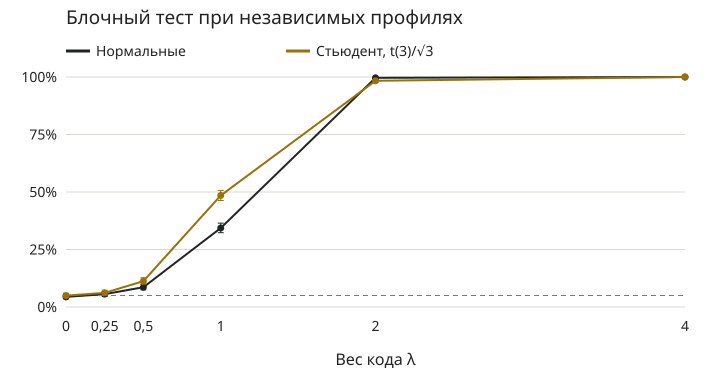

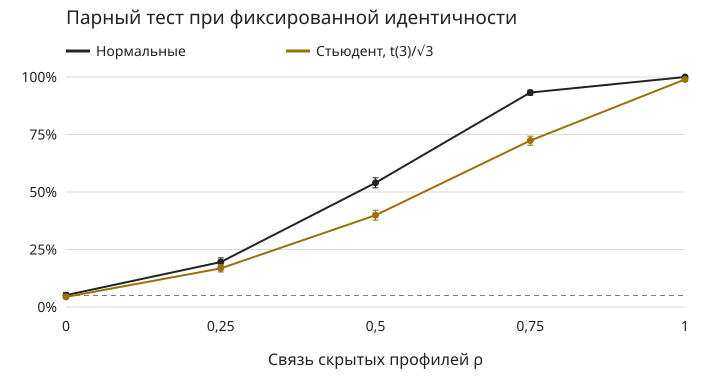

In [ ]:
def rejection_plot(rows, x_column, x_label, title, alpha):
    width, height = 720, 390
    left, right, top, bottom = 66, 685, 77, 307
    ticks = np.sort(rows[x_column].unique())
    def px(value):
        return left + (right - left) * (value - ticks[0]) / (ticks[-1] - ticks[0])
    def py(value):
        return bottom - (bottom - top) * value
    def label(x, y, value, anchor="middle", size=14):
        return (f'<text x="{x:.2f}" y="{y:.2f}" text-anchor="{anchor}" '
                f'font-family="sans-serif" font-size="{size}" fill="#20231f">{escape(str(value))}</text>')
    def line(x1, y1, x2, y2, color, extra=""):
        return (f'<line x1="{x1:.2f}" y1="{y1:.2f}" x2="{x2:.2f}" y2="{y2:.2f}" '
                f'stroke="{color}" {extra}/>')
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" '
             f'viewBox="0 0 {width} {height}" role="img"><title>{escape(title)}</title>',
             '<rect width="100%" height="100%" fill="white"/>', label(left, 24, title, "start", 19)]
    for value in np.linspace(0, 1, 5):
        parts.extend([line(left, py(value), right, py(value), "#d9dcd1"),
                      label(left - 9, py(value) + 5, f"{value:.0%}", "end")])
    for tick in ticks:
        parts.append(label(px(tick), bottom + 24, f"{tick:g}".replace(".", ",")))
    parts.append(label((left + right) / 2, bottom + 58, x_label, size=16))
    parts.append(line(left, py(alpha), right, py(alpha), "#7a7c74", 'stroke-dasharray="5 4"'))
    for j, (key, color, caption) in enumerate([("normal", "#202523", "Нормальные"),
                                                 ("t3", "#997009", "Стьюдент, t(3)/√3")]):
        group = rows[rows.distribution == key].sort_values(x_column)
        points = []
        for _, row in group.iterrows():
            x, y = px(row[x_column]), py(row.rate)
            points.append(f"{x:.2f},{y:.2f}")
            parts.append(line(x, py(row.ci_low), x, py(row.ci_high), color))
            for bound in (row.ci_low, row.ci_high):
                parts.append(line(x - 3, py(bound), x + 3, py(bound), color))
            parts.append(f'<circle cx="{x:.2f}" cy="{y:.2f}" r="3.5" fill="{color}"/>')
        coords = " ".join(points)
        parts.append(f'<polyline points="{coords}" fill="none" stroke="{color}" stroke-width="2"/>')
        key_x = left + 220 * j
        parts += [line(key_x, 51, key_x + 24, 51, color, 'stroke-width="3"'),
                  label(key_x + 30, 56, caption, "start")]
    return SVG("".join(parts) + "</svg>")

display(rejection_plot(block_results.query("rho == 0"), "identity_weight", "Вес кода λ",
                       "Блочный тест при независимых профилях", ALPHA))
display(rejection_plot(paired_results, "rho", "Связь скрытых профилей ρ",
                       "Парный тест при фиксированной идентичности", ALPHA))

### Проверка на расширенных векторах

Для собственного эталона сокращение идентификационной части можно проверить без аналитической формулы расстояния. В следующей ячейке к четырём координатам каждого вектора явно присоединяется десятикомпонентный код. Проверяются все десять разностей и точное $p$-значение при нескольких весах кода, включая значение 100.

In [ ]:
def compare_augmented_identity(weight_values):
    rng = np.random.Generator(np.random.PCG64(42))
    shape = (N, T, D)
    anchor, main, baseline = (rng.normal(size=shape) for _ in range(3))
    def contrast(b, f, a):
        return (((b-a)**2).sum(axis=-1) - ((f-a)**2).sum(axis=-1)).mean(axis=-1)
    reference = contrast(baseline, main, anchor)
    expected_p = exact_paired_p(reference[None, :])[0]
    checks = []
    for weight in weight_values:
        identity = np.broadcast_to(weight * np.eye(N)[:, None, :], (N, T, N))
        extended = [np.concatenate([values, identity], axis=-1) for values in (baseline, main, anchor)]
        actual = contrast(*extended)
        actual_p = exact_paired_p(actual[None, :])[0]
        np.testing.assert_allclose(actual, reference, rtol=0, atol=1e-12)
        assert actual_p == expected_p
        checks.append({"λ": weight, "max |δ с кодом − δ без кода|": abs(actual-reference).max(),
                       "Точное p": actual_p})
    return pd.DataFrame(checks)

display(compare_augmented_identity([0, 0.25, 1, 4, 100]).round(12))

,λ,max |δ с кодом − δ без кода|,Точное p
0,0.00,0.0,0.904297
1,0.25,0.0,0.904297
2,1.00,0.0,0.904297
3,4.00,0.0,0.904297
4,100.00,0.0,0.904297


### Сверка с контрольными значениями статьи

Сравниваются неокруглённые расчётные значения и опубликованные ориентиры. Для округлённых строк таблицы 1 допуск соответствует половине единицы последнего разряда. Для перестановочных тестов сверяются целые числа отклонений. При уменьшении числа реализаций значения изменятся, поэтому проверка чисел статьи выполняется только при исходных объёмах и уровне значимости.

In [ ]:
def verify_paper_results():
    normal = grid_df.query("seed == 20261031 and distribution == 'normal' and rho == 0 and tau == 0.5")
    observed = normal.set_index("identity_weight").loc[[0., 2., 4.], "mean"]
    np.testing.assert_allclose(observed, [.197, .714, .997], atol=.0005, rtol=0)
    matched = equal_accuracy_df.set_index("distribution").loc[["normal", "t3"]]
    np.testing.assert_allclose(matched.full_style_A, [.77895, .72410], atol=5e-6, rtol=0)
    np.testing.assert_allclose(matched.full_style_A, matched.identity_only_A, atol=1e-12, rtol=0)
    scenario_counts = scenario_results.pivot(index="scenario", columns="distribution", values="rejections")
    scenario_counts = scenario_counts.loc[["null","partial","identity_only","wrong_donor"], ["normal","t3"]]
    np.testing.assert_array_equal(scenario_counts.to_numpy(), [[88,99],[1615,1458],[1993,1967],[0,0]])
    paired_counts = paired_results.pivot(index="rho", columns="distribution", values="rejections")
    paired_counts = paired_counts.loc[[0,.25,.5,.75,1.], ["normal","t3"]]
    np.testing.assert_array_equal(paired_counts.to_numpy(), [[103,88],[391,336],[1080,798],[1865,1447],[2000,1979]])
    print("Точность, две пары равной точности и числа отклонений из таблиц 2 и 3 подтверждены.")

if GRID_REPLICATIONS == 1000 and N_TEST == 2000 and TEST_TAU == .5 and ALPHA == .05:
    verify_paper_results()
else:
    print("Использован изменённый дизайн. Сверка с фиксированными значениями статьи пропущена.")

Точность, две пары равной точности и числа отклонений из таблиц 2 и 3 подтверждены.


## Собственное условие на одной модельной выборке

Функция ниже применяет обе процедуры к одним и тем же объектам. Можно изменить связь профилей, величину возмущения, вес кода или распределение. При фиксированном начальном состоянии сохраняются исходные случайные компоненты. Это удобно для проверки того, как меняется результат при изменении только одного параметра.

В примере одна выборка. Её точность и $p$-значения описывают конкретную реализацию. Мощность теста оценивается по множеству независимых реализаций в предыдущем разделе.

In [ ]:
def evaluate_condition(rho, tau, weight, distribution="normal", seed=541):
    cohort = base(seed, 1, distribution)
    signal, independent, anchors, session, residual = cohort
    styles = distances(cohort, rho, tau)
    mixed = contaminate(styles, weight)
    block_p = enumerate_block_test(styles, [weight])[0][0, 0]
    independent_rng = np.random.Generator(np.random.PCG64(seed + 1))
    baseline = (draw(independent_rng, independent.shape, distribution) + tau * session
                + .35 * draw(independent_rng, residual.shape, distribution))
    own = styles[:, :, group_indices, group_indices, :]
    baseline_own = ((baseline - anchors)**2).sum(axis=-1)
    delta = (baseline_own - own).mean(axis=-1).reshape(1, N)
    return {"ρ": rho, "τ": tau, "λ": weight, "Распределение": distribution,
            "Точность A": scores(mixed)[0], "Общее p": block_p,
            "Средняя разность δ": delta.mean(), "Парное p": exact_paired_p(delta)[0]}

conditions = [(0., .5, 0.), (0., .5, 2.), (0., .5, 4.), (1., .5, 4.)]
example_results = pd.DataFrame([evaluate_condition(*condition) for condition in conditions])
display(example_results.round(6))
np.testing.assert_allclose(example_results.loc[:2, "Парное p"], example_results.loc[0, "Парное p"])

,ρ,τ,λ,Распределение,Точность A,Общее p,Средняя разность δ,Парное p
0,0.0,0.5,0.0,normal,0.291667,0.065833,1.797535,0.299805
1,0.0,0.5,2.0,normal,0.825000,0.000069,1.797535,0.299805
2,0.0,0.5,4.0,normal,1.000000,0.000069,1.797535,0.299805
3,1.0,0.5,4.0,normal,1.000000,0.000069,8.860638,0.000977


## Интерпретация результатов при параметрах статьи

- **Точность идентификации.** При независимых профилях, нормальных компонентах и $\tau=0{,}5$ увеличение веса кода с 0 до 4 повышает среднюю точность с 19,7% до 99,7%. Код изменяет только расстояния до чужих эталонов.
- **Неоднозначность.** В первом запуске при нормальных компонентах средняя точность 77,9% получена и при полной связи без кода, и при независимых профилях с подобранным весом кода. Это равенство оценок на одной фиксированной тысяче реализаций.
- **Общее соответствие.** При $\rho=0$, $\lambda=2$ и нормальных компонентах блочный тест отклоняет свою нулевую гипотезу в 99,65% реализаций. Назначение эталонов в этом условии действительно информативно благодаря коду.
- **Перенос стиля.** Парная разность при сравнении со своим эталоном не зависит от веса кода. При $\rho=0$ оценки размера теста равны 5,15% и 4,40%. При $\rho=0{,}5$ мощность составляет 54,0% и 39,9% для нормальных компонент и тяжёлых хвостов соответственно.
- **Граница вывода.** Чтобы применить процедуру к речи, нужно проверить межсеансовую устойчивость акустических признаков и построить базовое условие с сопоставимой идентичностью. В модели эти свойства обеспечены конструкцией генератора.

### Приложение. Планирование отдельного речевого пилота

В вычислительном пакете есть вспомогательный расчёт для будущего исследования. Пусть для каждого из $n$ независимых дикторов получен один знак эффекта без ничьих, а $\pi$ — вероятность положительного знака. Тогда число положительных эффектов $K$ имеет биномиальное распределение. Для двустороннего критерия получаем область отклонения при $\pi=0{,}5$ и суммируем её вероятности при альтернативе $\pi=0{,}75$. Также находим минимальное $\pi$, при котором мощность достигает 80%.

Этот расчёт характеризует дискретный знаковый критерий при планировании объёма выборки. Он отделён от парного перестановочного теста выше. В таблице сопоставлены уровень 0,05 для одной проверки и уровень 0,05/6 при поправке Бонферрони на шесть проверок.

In [ ]:
def sign_test_plan(n, alpha, target_power=.8):
    outcomes = range(n + 1)
    def mass(k, probability):
        return math.comb(n, k) * probability**k * (1-probability)**(n-k)
    critical = [k for k in outcomes
                if min(1., 2 * sum(mass(j, .5) for j in range(min(k, n-k) + 1))) <= alpha]
    def power(probability):
        return sum(mass(k, probability) for k in critical)
    low, high = .5, 1.
    for _ in range(70):
        mid = (low + high) / 2
        if power(mid) < target_power:
            low = mid
        else:
            high = mid
    return {"n": n, "alpha": alpha, "null_size": power(.5), "power_p075": power(.75),
            "p_for_power80": high if power(1.) >= target_power else np.nan}

pilot_plan = pd.DataFrame([sign_test_plan(n, level) for n in (10, 20, 30, 50)
                           for level in (.05, .05/6)])
display(pilot_plan.round(5))

,n,alpha,null_size,power_p075,p_for_power80
0,10,0.05000,0.02148,0.24405,0.91674
1,10,0.00833,0.00195,0.05631,0.97793
2,20,0.05000,0.04139,0.61718,0.79872
3,20,0.00833,0.00258,0.22516,0.88295
4,30,0.05000,0.04277,0.80341,0.74907
5,30,0.00833,0.00522,0.51429,0.80920
6,50,0.05000,0.03284,0.94488,0.70393
7,50,0.00833,0.00660,0.83692,0.74160


### Сохранение расчётных таблиц

Для дальнейшего анализа можно записать таблицы в один ZIP-архив. Укажите новое имя в последней ячейке и выберите `SAVE_TABLES = True`. По умолчанию данные остаются только в памяти ноутбука. При совпадении имени с существующим файлом Python остановит запись.

In [ ]:
SAVE_TABLES = False
archive_path = Path("Результаты_модельного_эксперимента.zip")
result_tables = {
    "sensitivity.csv": grid_df, "accuracy_thresholds.csv": thresholds_df,
    "equal_accuracy.csv": equal_accuracy_df, "block_scenarios.csv": scenario_results,
    "block_curves.csv": block_results, "paired_test.csv": paired_results,
    "rejection_thresholds.csv": rejection_boundaries, "pilot_plan.csv": pilot_plan,
}
if SAVE_TABLES:
    archive = BytesIO()
    with ZipFile(archive, mode="w", compression=ZIP_DEFLATED) as package:
        for filename, frame in result_tables.items():
            package.writestr(filename, frame.to_csv(index=False).encode("utf-8-sig"))
    with archive_path.open("xb") as target:
        target.write(archive.getvalue())
    print(archive_path.resolve())